# Data cleaning

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
df=pd.read_csv("ElectricCarData_Clean.csv")

In [16]:
df

,Brand,Model,AccelSec,TopSpeed_KmH,Range_Km,Efficiency_WhKm,FastCharge_KmH,RapidCharge,PowerTrain,PlugType,BodyStyle,Segment,Seats,PriceEuro
0,Tesla,Model 3 Long Range Dual Motor,4.6,233,450,161,940,Yes,AWD,Type 2 CCS,Sedan,D,5,55480
1,Volkswagen,ID.3 Pure,10.0,160,270,167,250,Yes,RWD,Type 2 CCS,Hatchback,C,5,30000
2,Polestar,2,4.7,210,400,181,620,Yes,AWD,Type 2 CCS,Liftback,D,5,56440
3,BMW,iX3,6.8,180,360,206,560,Yes,RWD,Type 2 CCS,SUV,D,5,68040
4,Honda,e,9.5,145,170,168,190,Yes,RWD,Type 2 CCS,Hatchback,B,4,32997
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,Nissan,Ariya 63kWh,7.5,160,330,191,440,Yes,FWD,Type 2 CCS,Hatchback,C,5,45000
99,Audi,e-tron S Sportback 55 quattro,4.5,210,335,258,540,Yes,AWD,Type 2 CCS,SUV,E,5,96050
100,Nissan,Ariya e-4ORCE 63kWh,5.9,200,325,194,440,Yes,AWD,Type 2 CCS,Hatchback,C,5,50000
101,Nissan,Ariya e-4ORCE 87kWh Performance,5.1,200,375,232,450,Yes,AWD,Type 2 CCS,Hatchback,C,5,65000


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            103 non-null    object 
 1   Model            103 non-null    object 
 2   AccelSec         103 non-null    float64
 3   TopSpeed_KmH     103 non-null    int64  
 4   Range_Km         103 non-null    int64  
 5   Efficiency_WhKm  103 non-null    int64  
 6   FastCharge_KmH   103 non-null    object 
 7   RapidCharge      103 non-null    object 
 8   PowerTrain       103 non-null    object 
 9   PlugType         103 non-null    object 
 10  BodyStyle        103 non-null    object 
 11  Segment          103 non-null    object 
 12  Seats            103 non-null    int64  
 13  PriceEuro        103 non-null    int64  
dtypes: float64(1), int64(5), object(8)
memory usage: 11.4+ KB


In [18]:
df.describe()

,AccelSec,TopSpeed_KmH,Range_Km,Efficiency_WhKm,Seats,PriceEuro
count,103.000000,103.000000,103.000000,103.000000,103.000000,103.000000
mean,7.396117,179.194175,338.786408,189.165049,4.883495,55811.563107
std,3.017430,43.573030,126.014444,29.566839,0.795834,34134.665280
min,2.100000,123.000000,95.000000,104.000000,2.000000,20129.000000
25%,5.100000,150.000000,250.000000,168.000000,5.000000,34429.500000
50%,7.300000,160.000000,340.000000,180.000000,5.000000,45000.000000
75%,9.000000,200.000000,400.000000,203.000000,5.000000,65000.000000
max,22.400000,410.000000,970.000000,273.000000,7.000000,215000.000000


In [19]:
df.isnull().sum()

Brand              0
Model              0
AccelSec           0
TopSpeed_KmH       0
Range_Km           0
Efficiency_WhKm    0
FastCharge_KmH     0
RapidCharge        0
PowerTrain         0
PlugType           0
BodyStyle          0
Segment            0
Seats              0
PriceEuro          0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

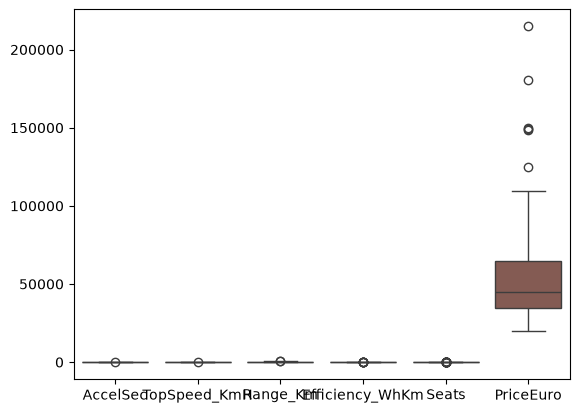

In [24]:
sns.boxplot(df)
plt.show()

In [26]:
# drop column
df.drop("Brand",axis=1,inplace=True)

In [28]:
# model column
df.drop("Model",axis=1,inplace=True)

In [36]:

# "FastCharge_KmH" column

df["FastCharge_KmH"]=pd.to_numeric(df["FastCharge_KmH"],errors="coerce")
df["FastCharge_KmH"]



0      940.0
1      250.0
2      620.0
3      560.0
4      190.0
       ...  
98     440.0
99     540.0
100    440.0
101    450.0
102    480.0
Name: FastCharge_KmH, Length: 103, dtype: float64

In [35]:
# RapidCharge column

df["RapidCharge"].value_counts()

df["RapidCharge"]=df["RapidCharge"].replace({"Yes":1,"No":0})

df["RapidCharge"]

0      1
1      1
2      1
3      1
4      1
      ..
98     1
99     1
100    1
101    1
102    1
Name: RapidCharge, Length: 103, dtype: int64

In [42]:
# PowerTrain column

df["PowerTrain"].value_counts()

df["PowerTrain"]=df["PowerTrain"].map({"AWD":1,"FWD":2,"RWD":3})

In [44]:
# PlugType column

df["PlugType"].value_counts()

df.drop("PlugType",axis=1,inplace=True)

In [46]:
# BodyStyle column
df["BodyStyle"].value_counts()

df.drop("BodyStyle",axis=1,inplace=True)

In [47]:
# Segment column
df.drop("Segment",axis=1,inplace=True)

In [49]:
# Seats
df["Seats"].value_counts()

Seats
5    71
4    21
7     6
6     3
2     2
Name: count, dtype: int64

In [50]:
# PriceEuro
df["PriceEuro"].value_counts()

PriceEuro
45000    6
50000    3
30000    2
35000    2
65000    2
        ..
37900    1
35575    1
53500    1
96050    1
62000    1
Name: count, Length: 87, dtype: int64

### Model Training

In [51]:
# divide the datset

X=df.drop("PriceEuro",axis=1)
y=df["PriceEuro"]

In [52]:
#  splitting th model 

from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2)

In [60]:
from sklearn.tree import DecisionTreeRegressor

DTR=DecisionTreeRegressor()

modle=DTR.fit(X_train,y_train)

y_pred=modle.predict(X_test)


In [63]:
from sklearn.metrics import accuracy_score,mean_squared_error,mean_absolute_error,r2_score

accuracy=accuracy_score(y_test,y_pred)
print("Accuracy Score: ",accuracy)

MAE=mean_absolute_error(y_test,y_pred)
print("MAE : ",MAE)

MSE=mean_squared_error(y_test,y_pred)
print("MSE : ",MSE)

r2=r2_score(y_test,y_pred)
print("R2_SCORE: ",r2)


Accuracy Score:  0.047619047619047616
MAE :  8211.952380952382
MSE :  189019311.76190478
R2_SCORE:  0.7616515274814328
